In [1]:
print('hola')

hola


Dataset de retornos logarítmicos de las 30 empresas:

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np

djia_tickers = [
    "AAPL", "AMGN", "AXP", "BA", "CAT", "CRM", "CSCO", "CVX", "DIS", 
    "GS", "HD", "HON", "IBM", "INTC", "JNJ", "JPM", "KO", "MCD", "MMM",
    "MRK", "MSFT", "NKE", "PG", "TRV", "UNH", "V", "VZ", "WMT", "AMZN"
]

print("Descargando precios...")
datos = yf.download(djia_tickers, start="2008-03-20", interval="1d")
# Extracción robusta de los precios de cierre
try:
    # Intenta buscar en el primer nivel (comportamiento clásico)
    precios = datos['Adj Close']
except KeyError:
    try:
        # Intenta buscar en el segundo nivel usando cross-section (comportamiento nuevo)
        precios = datos.xs('Adj Close', level=1, axis=1)
    except KeyError:
        # Fallback por si la métrica fue renombrada simplemente a 'Close'
        try:
            precios = datos['Close']
        except KeyError:
            precios = datos.xs('Close', level=1, axis=1)

# 1. Eliminamos acciones que no existían hace 15 años (ej. si tienen más de 10 NaNs)
precios = precios.dropna(axis=1, thresh=len(precios) - 10)

# 2. Calculamos retornos logarítmicos
retornos_log = np.log(precios / precios.shift(1))

# 3. Borramos días aislados con fallos
retornos_log = retornos_log.dropna(axis=0, how='any')

print(f"Dimensiones finales: {retornos_log.shape[0]} días, {retornos_log.shape[1]} acciones.")
retornos_log.to_csv("retornos_log_djia_18y.csv")
print("Archivo 'retornos_log_djia_18y.csv' generado con éxito.")

Descargando precios...


[*********************100%***********************]  29 of 29 completed

Dimensiones finales: 4683 días, 29 acciones.
Archivo 'retornos_log_djia_15y.csv' generado con éxito.


csv de la volatilidad:

In [2]:
import pandas as pd
import numpy as np

# 1. Cargás los datos crudos (tu CSV actual)
retornos = pd.read_csv("retornos_log_djia_18y.csv", index_col=0, parse_dates=True)

# 2. Retorno diario del mercado (promedio de todas las acciones)
r_mercado = retornos.mean(axis=1)

# 3. Calculás la volatilidad (desviación estándar a 5 días) y la desplazás hacia "atrás"
vol_futura_5d = r_mercado.rolling(window=5).std().shift(-5)

# Las últimas 5 filas van a dar NaN porque no tienen 5 días de futuro para calcular
vol_futura_5d = vol_futura_5d.dropna()

# Este objeto 'vol_futura_5d' es tu variable a predecir (y) en formato continuo.
print(vol_futura_5d.head())

vol_futura_5d.to_csv("volatilidad.csv")

Date
2008-03-24    0.008321
2008-03-25    0.019222
2008-03-26    0.018510
2008-03-27    0.015884
2008-03-28    0.015166
dtype: float64


cvs de features financieras clásicas:

In [4]:
import pandas as pd

# 1. Cargar los retornos limpios
retornos = pd.read_csv("retornos_log_djia_18y.csv", index_col=0, parse_dates=True)

# 2. Calcular el retorno diario del mercado (promedio de las 29 acciones)
r_mercado = retornos.mean(axis=1)

# 3. Crear un DataFrame vacío con el mismo índice temporal para guardar las features
df_features = pd.DataFrame(index=retornos.index)
ventana = 30

# 4. Calcular las features financieras rodantes (rolling)
df_features['retorno_medio_30d'] = r_mercado.rolling(window=ventana).mean()
df_features['volatilidad_30d'] = r_mercado.rolling(window=ventana).std()
df_features['momento_30d'] = r_mercado.rolling(window=ventana).sum()
df_features['caida_maxima_30d'] = r_mercado.rolling(window=ventana).min()

# 5. Limpieza de bordes: Los primeros 29 días dan NaN porque la ventana no está llena
df_features = df_features.dropna()

# 6. Guardar la matriz X del baseline
df_features.to_csv("features_financieras_basicas.csv")

print(f"Dataset de features clásicas generado.")
print(f"Dimensiones: {df_features.shape[0]} filas x {df_features.shape[1]} columnas")
print(df_features.head())

Dataset de features clásicas generado.
Dimensiones: 4654 filas x 4 columnas
            retorno_medio_30d  volatilidad_30d  momento_30d  caida_maxima_30d
Date                                                                         
2008-05-02           0.002506         0.011507     0.075168         -0.021044
2008-05-05           0.001855         0.011330     0.055647         -0.021044
2008-05-06           0.001918         0.011337     0.057541         -0.021044
2008-05-07           0.001734         0.011588     0.052012         -0.021044
2008-05-08           0.002226         0.011158     0.066774         -0.021044


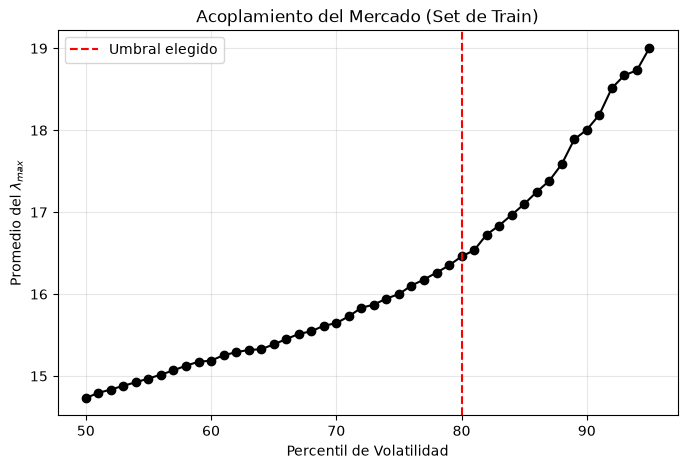

In [6]:
import matplotlib.pyplot as plt
import numpy as np

retornos = pd.read_csv("retornos_log_djia_18y.csv", index_col=0, parse_dates=True)

# Si no tenés el lambda_max en X_train, descomentá esto para calcularlo (toma unos segundos):
retornos_train = retornos.loc[vol_train.index]
corrs = retornos_train.rolling(window=21).corr().dropna(how='all') # ventana típica de 1 mes
lambda_max_train = corrs.groupby(level=0).apply(lambda x: np.linalg.eigvalsh(x.values)[-1])

# Si ya lo tenés en tus features, usá directamente tu columna (ajustá el nombre):
#lambda_max_train = X_train['lambda_max'] 

percentiles = np.arange(50, 96, 1)
promedios_lambda = []

for p in percentiles:
    umbral_p = np.percentile(vol_train, p)
    # Filtramos los días donde la volatilidad supera el percentil p
    mascara = vol_train >= umbral_p
    # Calculamos el lambda_max promedio de ese régimen
    promedio = lambda_max_train[mascara].mean()
    promedios_lambda.append(promedio)

# Graficamos la transición de fase
plt.figure(figsize=(8, 5))
plt.plot(percentiles, promedios_lambda, marker='o', linestyle='-', color='black')
plt.title('Acoplamiento del Mercado (Set de Train)')
plt.xlabel('Percentil de Volatilidad')
plt.ylabel('Promedio del $\lambda_{max}$')
plt.grid(True, alpha=0.3)

# Podés agregar una línea vertical provisoria donde a ojo veas el codo
plt.axvline(x=80, color='red', linestyle='--', label='Umbral elegido')
plt.legend()

plt.show()

Split

In [13]:
import pandas as pd
import numpy as np

# 1. Cargás tus features (X) y asumimos que ya tenés vol_futura_5d calculada
X = pd.read_csv("features_financieras_basicas.csv", index_col=0, parse_dates=True)

vol_futura_5d = pd.read_csv("volatilidad.csv", index_col=0, parse_dates=True)

# 2. Las unimos en un único DataFrame para alinearlas por fecha
df_completo = X.copy()
df_completo['target_continuo'] = vol_futura_5d

# 3. Purga maestra: elimina filas donde falte X (por ej. medias móviles iniciales) 
# o falte y (los últimos 5 días que no tienen futuro). 
# Esto garantiza que X e y tengan exactamente la misma cantidad de filas.
df_completo = df_completo.dropna()

print(f"Filas limpias y alineadas: {len(df_completo)}")

# 4. Separamos de nuevo en X e y ya perfectamente alineados
X_alineado = df_completo.drop(columns=['target_continuo'])
y_alineado = df_completo['target_continuo']

# 5. Definimos los cortes y el horizonte de purga
total_filas = len(df_completo)
corte_1 = int(total_filas * 0.70)
corte_2 = int(total_filas * 0.85)
horizonte = 5  # Días de gap para evitar filtración de datos (data leakage)

# 6. Aplicamos los cortes cronológicos con el horizonte de seguridad

# Train: frenamos 5 días antes del corte_1 para no pisar el futuro de Validation
X_train = X_alineado.iloc[:corte_1 - horizonte]
vol_train = y_alineado.iloc[:corte_1 - horizonte]

# Validation: arranca en corte_1 y frena 5 días antes de corte_2
X_val = X_alineado.iloc[corte_1 : corte_2 - horizonte]
vol_val = y_alineado.iloc[corte_1 : corte_2 - horizonte]

# Test: arranca limpio en corte_2 hasta el final
X_test = X_alineado.iloc[corte_2:]
vol_test = y_alineado.iloc[corte_2:]

# 7. Calculamos el umbral SOLO con el set de Train ya purgado
umbral = np.percentile(vol_train, 75)

# 8. Binarizamos los tres sets usando ese umbral
y_train = (vol_train > umbral).astype(int)
y_val   = (vol_val > umbral).astype(int)
y_test  = (vol_test > umbral).astype(int)

Filas limpias y alineadas: 4649


Entreno del modelo VSM y métricas:

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score, 
    average_precision_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix
    balanced_accuracy_score,
)

# 1. Escalado OBLIGATORIO
# .fit_transform() SOLO en train para no filtrar información del futuro
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 2. Definición y entrenamiento
# kernel='rbf': Permite separar datos con fronteras no lineales (curvas).
# probability=True: Obligatorio para poder calcular la métrica ROC-AUC.
# class_weight='balanced': Penaliza al modelo 4 veces más si se equivoca en un "1" 
#                          para compensar la relación 80/20 de tus datos.
svm_model = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# 3. Predicciones
y_pred = svm_model.predict(X_val_scaled) # Devuelve clase dura (0 o 1)
y_prob = svm_model.predict_proba(X_val_scaled)[:, 1] # Devuelve probabilidad (0.0 a 1.0)

# 4. Evaluación de Métricas
print("--- MÉTRICAS SOBRE EL SET DE val aisaldo ---")
print("--- MÉTRICAS DE DETECCIÓN DE CRISIS (CLASE 1) ---\n")
print(f"ROC-AUC (Global):          {roc_auc_score(y_val, y_prob):.4f}\n")
print(f"PR-AUC (Foco en clase 1):  {average_precision_score(y_val, y_prob):.4f}\n")
print(f"Precision (Alarma real):   {precision_score(y_val, y_pred):.4f}\n")
print(f"Recall (Crisis atrapadas): {recall_score(y_val, y_pred):.4f}\n")
print(f"F1-Score (Clase 1):        {f1_score(y_val, y_pred):.4f}\n")
print(f"Balanced Accuracy:         {balanced_accuracy_score(y_val, y_pred):.4f}")

print("Matriz de Confusión:")
print(confusion_matrix(y_val, y_pred))

SyntaxError: invalid syntax (1059317953.py, line 10)